In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup
import os

DATA_PATH = r'.\Raw Datasets'

# Hyperlinks datasets wrangling

<div class="alert alert-info">
Je vois pas d'utilité à garder les datasets title vs. body séparés pour notre cas donc je les combine
</div>

Read hyperlinks datasets in and combine them

In [147]:
hyperlinks_title_df = pd.read_csv(os.path.join(DATA_PATH, 'soc-redditHyperlinks-title.tsv'), sep='\t')
hyperlinks_body_df = pd.read_csv(os.path.join(DATA_PATH, 'soc-redditHyperlinks-body.tsv'), sep='\t')

hyperlinks_df = pd.concat([hyperlinks_title_df, hyperlinks_body_df], ignore_index=True) # ignore_index=True allows to reassign unique indices
hyperlinks_df.sample(10)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES
469020,excgarated,enoughtrumpspam,5ckk5ys,2016-11-12 21:14:12,1,"19.0,19.0,0.894736842105,0.0,0.263157894737,0...."
489516,awwwtf,funny,5iw4gxs,2016-12-18 02:36:06,1,"30.0,27.0,0.833333333333,0.0,0.2,0.13333333333..."
775431,the1975,todayilearned,4rk971s,2016-07-06 12:59:06,1,"719.0,620.0,0.780250347705,0.0125173852573,0.0..."
169836,subredditdrama,delusionalartists,31p58rs,2015-04-06 19:23:56,1,"155.0,131.0,0.806451612903,0.0,0.0387096774194..."
159268,bestedits,mildlyinteresting,2yyua1s,2015-03-13 17:41:40,1,"32.0,27.0,0.78125,0.0,0.1875,0.1875,0.03125,7...."
849295,wildlandsyeti,wildlandsthegame,62rzmks,2017-04-01 04:05:36,1,"2212.0,1851.0,0.76130198915,0.00678119349005,0..."
546029,badlinguistics,linguistics,60ufzls,2017-03-22 13:05:51,1,"73.0,62.0,0.780821917808,0.0,0.0821917808219,0..."
741034,china,dota2,48ligps,2016-03-02 01:18:54,1,"525.0,453.0,0.771428571429,0.00761904761905,0...."
760982,debatereligion,poetry,4ji5zgs,2016-05-15 15:02:20,1,"2460.0,2176.0,0.788617886179,0.00650406504065,..."
614108,stlouisrams,ravens,2fu4m0s,2014-09-08 13:12:59,1,"503.0,447.0,0.765407554672,0.0238568588469,0.0..."


Check for missing values or duplicate rows

In [148]:
has_duplicates = hyperlinks_df.duplicated(subset=['SOURCE_SUBREDDIT', 'TARGET_SUBREDDIT', 'POST_ID']).any()
print(f"Dataframe {'has' if has_duplicates else 'does not have'} duplicates")

has_missing = hyperlinks_df.isna().values.any() or hyperlinks_df.eq('').values.any()
print(f"Dataframe {'has' if has_missing else 'does not have'} missing values")

has_posts_with_multiple_targets = hyperlinks_df.groupby(['SOURCE_SUBREDDIT', 'POST_ID'])['TARGET_SUBREDDIT'].nunique().gt(1).any()
print(f"Dataframe {'has' if has_posts_with_multiple_targets else 'does not have'} posts with multiple target subreddits")

Dataframe does not have duplicates
Dataframe does not have missing values
Dataframe has posts with multiple target subreddits


<div class="alert alert-warning">
Qu'est-ce qu'on fait des posts qui ont des hyperlinks vers plusieurs subs? Par exemple s'il y a un post qui dit du bien d'un target et du mal d'un autre, le <i>LINK_SENTIMENT</i> ne ferait pas vraiment de sens vu qu'il ne pourrait pas différencier les deux
</div>

Remove posts with multiple target subreddits

In [149]:
multi_target_mask = hyperlinks_df.groupby(['SOURCE_SUBREDDIT', 'POST_ID'])['TARGET_SUBREDDIT'].transform('nunique') > 1
hyperlinks_df = hyperlinks_df.loc[~multi_target_mask]

Scrape the dataset info webpage to retrieve the list of post properties in order to make the dataframe more explicit

In [150]:
DATASET_INFO_PAGE_URL = 'https://snap.stanford.edu/data/soc-RedditHyperlinks.html'

request = requests.get(DATASET_INFO_PAGE_URL)
parsed_page = BeautifulSoup(request.text, 'html.parser')

In [151]:
def format_post_properties_description(description):
    """
    Format the raw post property description found on the dataset webpage into a suitable dataframe column name. The output is in SCREAMING_SNAKE_CASE

    Args:
        description (str): the raw post property description

    Returns:
        str: formatted column name
    """

    replacements_dict = {
        ', such as comma, exclamation mark, etc.' : '',
        '(at least 6 characters)' : '',
        '(at least 10 words)' : '',
        'calculated by VADER' : '',
        'number of' : 'nb',
        'fraction of' : 'frac',
        'characters' : 'chars',
        'average' : 'avg',
        'alphabetical' : 'alph',
        'uppercase' : 'upper',
        'works' : 'words',
        'positive' : 'pos',
        'negative' : 'neg',
        'compound' : 'comp',
        'without counting white space' : 'w/o white spaces'
    }

    description = description.lower()
    for original, replacement in replacements_dict.items():
        description = description.replace(original.lower(), replacement)
    description = description.strip().replace(' ', '_').upper()
    return description

In [152]:
post_properties = []

collect = False
for line in parsed_page.get_text().splitlines():
    line = line.strip()

    if line.startswith('POST_PROPERTIES'):
        collect = True # start collecting post properties starting from the line below 'POST_PROPERTIES'
        continue

    if collect:
        if line and line[0].isdigit():
            property_description = line.split('. ')[1]
            formatted_property_description = format_post_properties_description(property_description)
            post_properties.append(formatted_property_description)
        else:
            break # stop collecting once we reach a line that does not start with a number

print(post_properties)

['NB_CHARS', 'NB_CHARS_W/O_WHITE_SPACES', 'FRAC_ALPH_CHARS', 'FRAC_DIGITS', 'FRAC_UPPER_CHARS', 'FRAC_WHITE_SPACES', 'FRAC_SPECIAL_CHARS', 'NB_WORDS', 'NB_UNIQUE_WORDS', 'NB_LONG_WORDS', 'AVG_WORD_LENGTH', 'NB_UNIQUE_STOPWORDS', 'FRAC_STOPWORDS', 'NB_SENTENCES', 'NB_LONG_SENTENCES', 'AVG_NB_CHARS_PER_SENTENCE', 'AVG_NB_WORDS_PER_SENTENCE', 'AUTOMATED_READABILITY_INDEX', 'POS_SENTIMENT', 'NEG_SENTIMENT', 'COMP_SENTIMENT', 'LIWC_FUNCT', 'LIWC_PRONOUN', 'LIWC_PPRON', 'LIWC_I', 'LIWC_WE', 'LIWC_YOU', 'LIWC_SHEHE', 'LIWC_THEY', 'LIWC_IPRON', 'LIWC_ARTICLE', 'LIWC_VERBS', 'LIWC_AUXVB', 'LIWC_PAST', 'LIWC_PRESENT', 'LIWC_FUTURE', 'LIWC_ADVERBS', 'LIWC_PREP', 'LIWC_CONJ', 'LIWC_NEGATE', 'LIWC_QUANT', 'LIWC_NUMBERS', 'LIWC_SWEAR', 'LIWC_SOCIAL', 'LIWC_FAMILY', 'LIWC_FRIENDS', 'LIWC_HUMANS', 'LIWC_AFFECT', 'LIWC_POSEMO', 'LIWC_NEGEMO', 'LIWC_ANX', 'LIWC_ANGER', 'LIWC_SAD', 'LIWC_COGMECH', 'LIWC_INSIGHT', 'LIWC_CAUSE', 'LIWC_DISCREP', 'LIWC_TENTAT', 'LIWC_CERTAIN', 'LIWC_INHIB', 'LIWC_INCL', 'LIW

In [153]:
# Replace the single PROPERTIES column with one column per property
hyperlinks_df[post_properties] = hyperlinks_df['PROPERTIES'].str.split(',', expand=True).astype(float)
hyperlinks_df.drop(columns=['PROPERTIES'], inplace=True)
hyperlinks_df.sample(10)

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NB_CHARS,NB_CHARS_W/O_WHITE_SPACES,FRAC_ALPH_CHARS,FRAC_DIGITS,FRAC_UPPER_CHARS,...,LIWC_ACHIEV,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER
136370,machinelearning,programming,2t5tlrs,2015-01-21 02:11:31,1,137.0,119.0,0.802920,0.000000,0.116788,...,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.050000,0.000000,0.000000,0.0
564905,conspiracy,antisemitism,66k1ias,2017-04-20 12:30:42,1,73.0,66.0,0.876712,0.000000,0.095890,...,0.000000,0.000000,0.000000,0.000000,0.100000,0.100000,0.000000,0.000000,0.000000,0.0
723470,asktrp,theredpill,3yvbic,2015-12-30 20:03:03,-1,2237.0,1843.0,0.794367,0.003129,0.016093,...,0.015190,0.012658,0.007595,0.007595,0.000000,0.000000,0.000000,0.002532,0.007595,0.0
589597,skeptic,science,23npn8s,2014-04-21 23:39:57,1,736.0,693.0,0.748641,0.036685,0.029891,...,0.000000,0.008696,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
596620,subredditdrama,pics,2717hts,2014-06-01 09:05:23,1,559.0,521.0,0.717352,0.051878,0.014311,...,0.000000,0.000000,0.000000,0.012658,0.012658,0.000000,0.000000,0.000000,0.000000,0.0
251970,justunsubbed,frugal,3llhpw,2015-09-20 02:11:37,-1,118.0,100.0,0.762712,0.000000,0.110169,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
400702,fuckthealtright,the_donald,4s1ppds,2016-07-09 11:28:22,1,63.0,55.0,0.809524,0.000000,0.095238,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
58333,yawriters,writing,2956qes,2014-06-26 05:55:47,1,302.0,251.0,0.754967,0.006623,0.102649,...,0.000000,0.053571,0.017857,0.017857,0.000000,0.017857,0.017857,0.000000,0.000000,0.0
548621,shitpoliticssays,politicalhumor,61n7gos,2017-03-26 11:23:51,1,77.0,65.0,0.792208,0.000000,0.103896,...,0.133333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
791183,pokemongocalgary,thesilphroad,50mvvts,2016-09-01 07:26:14,1,831.0,698.0,0.790614,0.006017,0.038508,...,0.000000,0.006897,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0


# Subreddit embeddings dataset wrangling

Read subreddit embedding dataset in

In [154]:
sub_embeddings_df = pd.read_csv(os.path.join(DATA_PATH, 'web-redditEmbeddings-subreddits.csv'), sep=',', header=None)
sub_embeddings_df.sample(10)

,0,1,2,3,4,5,6,7,8,9,...,291,292,293,294,295,296,297,298,299,300
27237,minecraftpe,-0.009712,-0.106330,0.112816,-0.077034,0.012145,-0.046407,0.044697,-0.010813,-0.113273,...,0.036129,0.009180,-0.003884,0.059297,0.037061,-0.018836,-0.049850,-0.001712,0.051742,0.025143
40953,bonobo,-0.024085,-0.058701,0.063271,-0.061967,0.024479,-0.040148,0.056584,0.014815,-0.073827,...,0.032423,0.014650,-0.013944,0.040052,0.014877,-0.025441,-0.026577,-0.003384,0.047603,0.004871
2217,playrustlfg,-0.169572,-0.573932,0.413665,0.039975,-0.077311,-0.034041,-0.355031,-0.067085,-0.529613,...,0.236849,-0.350042,-0.075321,0.880972,0.101844,0.237532,0.147682,0.610037,0.171320,-0.298440
19615,neography,-0.022296,-0.104229,0.073819,-0.072934,-0.006220,-0.111847,0.062657,0.030194,-0.120799,...,0.036264,0.005648,-0.022324,0.073384,0.042067,0.028977,0.007352,0.013889,0.044847,0.011369
46321,priyankachopra,0.002964,-0.013237,0.050168,-0.038755,0.028630,-0.002142,0.031057,0.017698,-0.072441,...,-0.003147,0.034005,-0.008561,0.001825,0.011729,-0.057223,-0.044197,-0.023124,0.032847,0.042137
42248,pornforme,0.000338,-0.062312,0.047236,-0.045257,0.019379,-0.021403,0.014115,0.040268,-0.076062,...,-0.003813,-0.011917,-0.012132,0.057537,0.012738,0.000786,-0.025166,0.021706,0.040997,0.017760
35444,papafranku,-0.013685,-0.085703,0.093976,-0.068118,0.013599,-0.036793,0.043530,0.017291,-0.113745,...,0.033061,-0.000621,-0.010971,0.055464,0.028383,-0.033440,-0.030639,-0.003276,0.063542,-0.000533
38476,cursive,-0.016820,-0.075114,0.074528,-0.060002,0.009026,-0.054255,0.053198,0.008371,-0.102235,...,0.031870,0.006536,-0.008524,0.040943,0.021678,-0.024578,-0.024446,0.014606,0.050259,0.012278
46540,ydnab,0.014634,-0.077525,0.062760,-0.043901,0.007210,-0.033266,0.046734,0.048317,-0.102296,...,-0.002611,0.001280,-0.002483,0.013094,0.021169,-0.043382,-0.043786,0.018966,0.038172,0.046726
38722,iwallpaperz,-0.014567,-0.060070,0.045878,-0.056464,0.040010,-0.013640,0.018204,0.003133,-0.052992,...,0.006742,0.004653,-0.002026,0.058154,0.011811,-0.005290,-0.028338,0.010290,0.023152,-0.003672


Check for missing values or duplicate rows

In [155]:
has_duplicates = sub_embeddings_df.duplicated(subset=0).any()
print(f"Dataframe {'has' if has_duplicates else 'does not have'} duplicates")

has_missing = sub_embeddings_df.isna().values.any() or sub_embeddings_df.eq('').values.any()
print(f"Dataframe {'has' if has_missing else 'does not have'} missing values")

Dataframe does not have duplicates
Dataframe does not have missing values


Give the name *SUBREDDIT* to the subreddits column and combine the individual embedding dimensions into a single *EMBED_VECTOR* column

In [156]:
sub_embeddings_df = pd.DataFrame({
    'SUBREDDIT': sub_embeddings_df.iloc[:, 0],
    'EMBED_VECTOR': sub_embeddings_df.iloc[:, 1:].to_numpy().tolist(),
})
sub_embeddings_df.sample(10)

,SUBREDDIT,EMBED_VECTOR
5505,cyberlaws,"[0.002095, 0.077416, -0.012541, -0.429546, -0...."
26325,eatwraps,"[0.034123, -0.047408, 0.077018, -0.104792, 0.0..."
17233,ahmadiyyat,"[-0.120143, -0.011104, -0.043452, -0.114166, 0..."
44530,totallytatro,"[-0.007686, -0.031242, 0.063161, -0.07908, 0.0..."
44528,a2pokemongo,"[-0.01217, -0.076528, 0.072367, -0.07408, 0.01..."
27340,nsfw_ladyboners,"[0.053242, -0.055941, 0.036477, 0.002369, 0.04..."
14253,themindsjournal,"[-0.037943, -0.05978, 0.314867, -0.157926, -0...."
12405,batteries,"[0.015099, -0.018505, 0.110779, -0.190932, -0...."
46112,ropetutorials,"[-0.004469, -0.06631, 0.060388, -0.04587, 0.01..."
13950,trueaustralia,"[0.029009, 0.013709, 0.086325, -0.208976, 0.13..."


# Isolating political communities

<div class="alert alert-info">
Je sais pas ce qui est mieux dans ce cas entre la euclidian distance, la cosine distance, ou une autre encore
</div>

Find the subreddits that are on average the closest to clearly political subreddits provided by ourselves

<div class="alert alert-danger">
One obvious issue with this method is that the results are biased towards the seed subreddits we specify
</div>

In [157]:
def embedding_distance_to_subs(sub_embeddings_df, subs):
    """
    Create a dataframe with the Euclidian embedding distances between all subreddits in a dataframe and reference ones. The distance between a subreddit and itself is set to None

    Args:
        sub_embeddings_df (pd.DataFrame): the subreddit embeddings dataframe
        subs (str): the reference subreddits' names

    Returns:
        pd.DataFrame: a dataframe with the embedding distances
    """

    result = sub_embeddings_df.drop(columns=['EMBED_VECTOR']).copy()
    for sub in subs:
        target_embedding = sub_embeddings_df.loc[sub_embeddings_df['SUBREDDIT'] == sub]['EMBED_VECTOR'].iloc[0]
        result['DIST_' + sub] = sub_embeddings_df['EMBED_VECTOR'].apply(lambda embedding: None if embedding == target_embedding else np.linalg.norm(np.asarray(embedding) - np.asarray(target_embedding))) # Euclidian distance
    return result

In [158]:
seed_subreddits = ['politics', 'republicans', 'democrats', 'worldnews', 'politicaldiscussion', 'politicalhumor']

dist_to_subs_df = embedding_distance_to_subs(sub_embeddings_df, seed_subreddits)
dist_to_subs_df['MEAN_DIST'] = dist_to_subs_df[['DIST_' + sub for sub in seed_subreddits]].mean(axis=1, skipna=True)
dist_to_subs_df['STD_DIST'] = dist_to_subs_df[['DIST_' + sub for sub in seed_subreddits]].std(axis=1, skipna=True)
dist_to_subs_df.sort_values('MEAN_DIST', ascending=True, inplace=True)

In [159]:
from kneed import KneeLocator

def determine_threshold(dist_to_subs_df):
    """
    Determine rank and distance thresholds for subreddits to be considered close to the seed subreddits. This is done by identifying the first knee of the distribution of sorted average embedding distances

    Args:
        dist_to_subs_df (pd.DataFrame): the dataframe with the mean embedding distances

    Returns:
        Tuple[int, float]: the rank and corresponding distance thresholds
    """

    median = dist_to_subs_df['MEAN_DIST'].median()
    y = dist_to_subs_df['MEAN_DIST'].loc[dist_to_subs_df['MEAN_DIST'].lt(median)].values # keep only the first half to have a concave, increasing distribution
    kl = KneeLocator(range(len(y)), y, curve='concave', direction='increasing')
    return kl.knee, kl.knee_y

threshold_rank, threshold_dist = determine_threshold(dist_to_subs_df)
print(f"Threshold rank: {threshold_rank} | Threshold distance: {threshold_dist:.3f}")
dist_to_subs_df[:threshold_rank]

Threshold rank: 287 | Threshold distance: 9.439


,SUBREDDIT,DIST_politics,DIST_republicans,DIST_democrats,DIST_worldnews,DIST_politicaldiscussion,DIST_politicalhumor,MEAN_DIST,STD_DIST
1463,liberal,12.038433,5.000241,2.826317,15.010997,6.498613,5.948552,7.887192,4.639285
4139,esist,12.879294,3.205792,5.839962,15.023536,6.606586,5.959978,8.252525,4.615375
4251,obama,13.257677,2.961425,5.291204,14.782234,7.405759,6.033541,8.288640,4.692268
2615,northcarolina,13.128842,3.395346,5.565285,15.335150,6.509341,6.036933,8.328483,4.746965
906,progressive,11.704815,6.441401,2.737104,15.084872,7.599832,6.636528,8.367425,4.364804
...,...,...,...,...,...,...,...,...,...
8655,whowillbuildtheroads,14.753888,2.803599,7.713473,16.025857,8.039412,7.244588,9.430136,5.008284
2327,snowden,14.187279,4.313562,6.696447,14.731289,9.119171,7.544656,9.432067,4.196111
5066,geography,14.619066,3.918980,7.608871,15.145479,7.980165,7.329945,9.433751,4.467508
12976,abolish,14.710062,3.301463,7.508520,15.471449,8.290425,7.320796,9.433786,4.719672


Plot the distribution of sorted average embedding distances

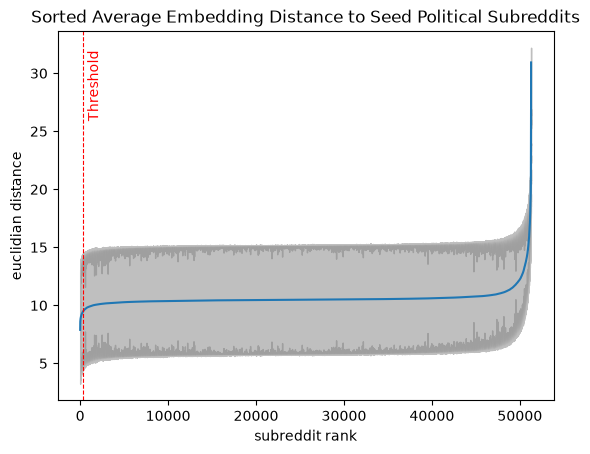

In [160]:
plt.figure()
plt.fill_between(range(len(dist_to_subs_df)), dist_to_subs_df['MEAN_DIST'].values - dist_to_subs_df['STD_DIST'].values, dist_to_subs_df['MEAN_DIST'].values + dist_to_subs_df['STD_DIST'].values, alpha = 0.5, color = 'gray')
plt.plot(dist_to_subs_df['MEAN_DIST'].values)
plt.axvline(threshold_rank, color='red', linestyle='--', linewidth=.8)
plt.text(threshold_rank + 500, .95 * plt.ylim()[1], 'Threshold', color='red', rotation=90, va='top', ha='left')
plt.title('Sorted Average Embedding Distance to Seed Political Subreddits')
plt.xlabel('subreddit rank')
plt.ylabel('euclidian distance')
plt.show()

Determine the list of political subreddits

In [161]:
political_subs = seed_subreddits + [sub for sub in dist_to_subs_df[:threshold_rank]['SUBREDDIT'].values.tolist() if sub not in seed_subreddits]
print(political_subs)

['politics', 'republicans', 'democrats', 'worldnews', 'politicaldiscussion', 'politicalhumor', 'liberal', 'esist', 'obama', 'northcarolina', 'progressive', 'wisconsin', 'impeach_trump', 'drumpf', 'hillaryforamerica', 'usnews', 'racism', 'florida', 'neutralnews', 'pennsylvania', 'lostgeneration', 'california', 'gunpolitics', 'randpaul', 'enoughsandersspam', 'media_criticism', 'political_revolution', 'worldevents', 'labor', 'ohio', 'usanews', 'journalism', 'ebola', 'truereddit', 'progun', 'satire', 'occupywallstreet', 'enoughlibertarianspam', 'americanpolitics', 'wikileaks', 'moderatepolitics', 'alabama', 'trump', 'alltheleft', 'newsofthestupid', 'enoughpaulspam', 'jillstein', 'anybodybuthillary', 'fuckthealtright', 'oregon', 'kansas', 'greenparty', 'conspiratard', 'feminism', 'minnesota', 'donaldtrumpsucks', 'restorethefourth', 'dncleaks', 'louisiana', 'media', 'texas', 'indiana', 'colorado', 'berniesanderssucks', 'veterans', 'georgia', 'guncontrol', 'highereducation', 'atheismrebooted'